In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [21]:
df = pd.read_csv("CarPrice_Assignment.csv")

df = df.sample(frac=1).reset_index(drop=True)
print(df.head())
print(df.shape)

   car_ID  symboling                  CarName fueltype aspiration doornumber  \
0      62          1         mazda glc custom      gas        std        two   
1     109          0              peugeot 304   diesel      turbo       four   
2      93          1             nissan latio      gas        std       four   
3     125          3          plymouth duster      gas      turbo        two   
4      72         -1  buick opel isuzu deluxe      gas        std       four   

     carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  hatchback        fwd          front       98.8  ...         122   
1      sedan        rwd          front      107.9  ...         152   
2      sedan        fwd          front       94.5  ...          97   
3  hatchback        rwd          front       95.9  ...         156   
4      sedan        rwd          front      115.6  ...         234   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrpm citympg  \
0        2bbl    

In [22]:
x = df[
    ['symboling',
     'wheelbase',
     'carlength',
     'carwidth',
     'carheight',
     'curbweight',
     'enginesize',
     'boreratio',
     'stroke',
     'compressionratio',
     'horsepower',
     'peakrpm',
     'citympg',
     'highwaympg']
].values

y = df['price'].values

In [23]:
m = len(x)

split = int(0.8 * m)

x_train = x[:split]
x_test = x[split:]

y_train = y[:split]
y_test = y[split:]

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (164, 14)
Testing data: (41, 14)


In [24]:
x_mean = np.mean(x_train, axis=0)
x_std = np.std(x_train, axis=0)

x_train = (x_train - x_mean) / x_std
x_test = (x_test - x_mean) / x_std

In [25]:
y_mean = np.mean(y_train)
y_std = np.std(y_train)

y_train = (y_train - y_mean) / y_std

In [26]:
n = x_train.shape[1]

w = np.zeros(n)
b = 0

print("Number of features:", n)

Number of features: 14


In [27]:
def compute_cost(x, y, w, b):

    m = x.shape[0]

    total_cost = 0

    for i in range(m):

        f = np.dot(x[i], w) + b

        total_cost += (f - y[i]) ** 2

    return total_cost / (2 * m)

In [28]:
def gradient_descent(x, y, w, b, alpha, iterations):
    m = x.shape[0]
    cost_history = []

    for i in range(iterations):
        dj_dw = np.zeros(len(w))
        dj_db = 0

        for j in range(m):
            f = np.dot(x[j], w) + b
            error = f - y[j]

            for k in range(len(w)):
                dj_dw[k] += error * x[j][k]

            dj_db += error

        dj_dw = dj_dw / m
        dj_db = dj_db / m

        for j in range(len(w)):
            w[j] = w[j] - alpha * dj_dw[j]

        b = b - alpha * dj_db

        cost_history.append(compute_cost(x, y, w, b))

    return w, b, cost_history

In [29]:
alpha = 0.01
iterations = 3000

w, b, cost_history = gradient_descent(
    x_train,
    y_train,
    w,
    b,
    alpha,
    iterations
)

print("Training complete")

Training complete


In [30]:
cost = compute_cost(x_train, y_train, w, b)

print("Final Cost:", cost)

Final Cost: 0.06884871648772958


In [31]:
predictions = np.zeros(len(x_test))

for i in range(len(x_test)):

    predictions[i] = np.dot(x_test[i], w) + b

In [32]:
predictions = predictions * y_std + y_mean

In [33]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': predictions
})

print(results.head(10))

   Actual Price  Predicted Price
0        7895.0      9963.404473
1        6377.0      6311.053339
2       12629.0     15883.201465
3       16430.0     13961.809877
4        5499.0      6522.612652
5        6479.0      2788.652481
6       15645.0     11072.321396
7       21485.0     24045.270168
8        8358.0      6260.857018
9       12170.0     14309.436383


In [34]:
mae = np.mean(np.abs(y_test - predictions))

print("Mean Absolute Error:", mae)

Mean Absolute Error: 2488.528077673978


In [35]:
rmse = np.sqrt(np.mean((y_test - predictions) ** 2))

print("RMSE:", rmse)

RMSE: 2938.3750589441706


In [36]:
ss_res = np.sum((y_test - predictions) ** 2)

ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print("R-squared:", r2)

R-squared: 0.7347094445440329


In [37]:
print("----- Final Results -----")

print("Mean Absolute Error:", mae)
print("RMSE:", rmse)
print("R-squared:", r2)

----- Final Results -----
Mean Absolute Error: 2488.528077673978
RMSE: 2938.3750589441706
R-squared: 0.7347094445440329


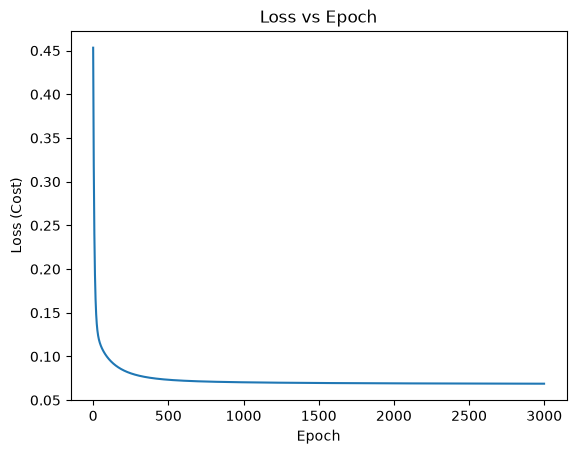

In [38]:
plt.plot(cost_history)

plt.xlabel("Epoch")
plt.ylabel("Loss (Cost)")
plt.title("Loss vs Epoch")

plt.show()

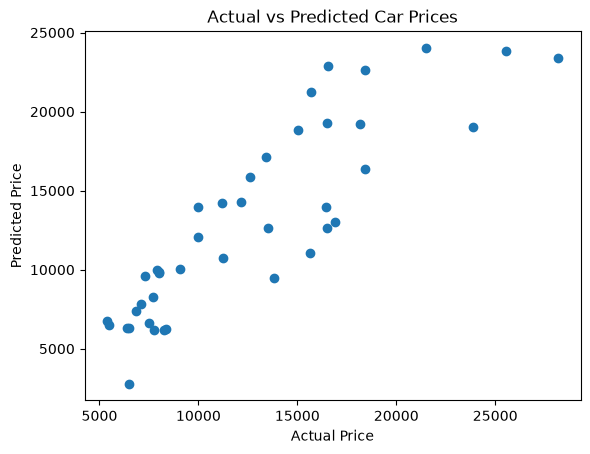

In [39]:
plt.scatter(y_test, predictions)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

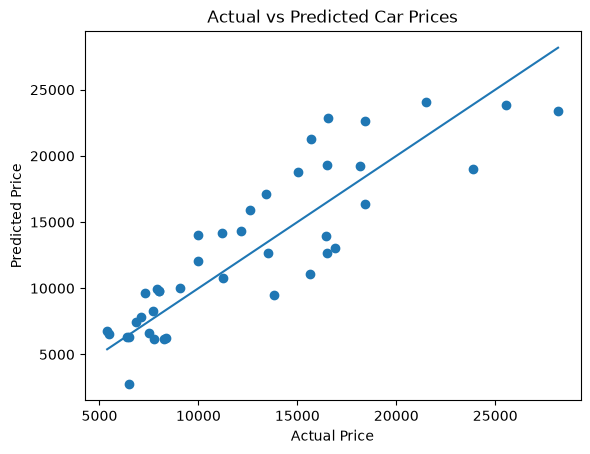

In [40]:
plt.scatter(y_test, predictions)

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)]
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

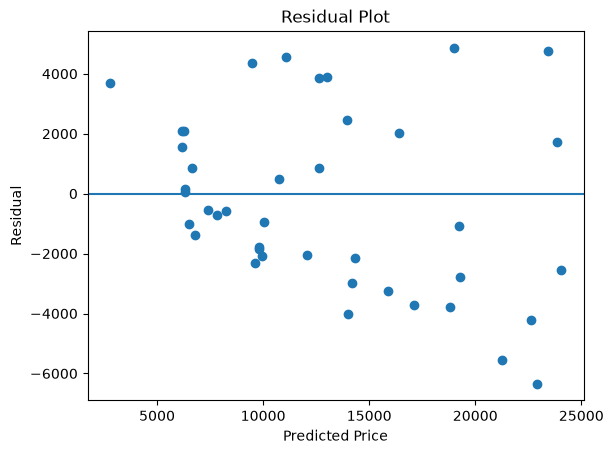

In [41]:
residuals = y_test - predictions

plt.scatter(predictions, residuals)
plt.axhline(y=0)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()